# NYC Taxi Fare Prediction Project

In this project, we'll apply the regression concepts we've learned to predict taxi fares in New York City. This is a comprehensive real-world project that combines data exploration, feature engineering, outlier detection, model building, and thorough evaluation.

We'll work with a dataset containing information about taxi rides in NYC, including pickup/dropoff locations, timestamps, passenger counts, and fare amounts. Our goal is to build a predictive model that can estimate the fare for a taxi ride based on these features.

This project will demonstrate how to apply linear regression to a messy real-world dataset while properly evaluating model performance using multiple metrics and diagnostic techniques.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

# Set style for better visualizations
sns.set_theme(style="whitegrid")
palette = sns.color_palette("rainbow", 8)

import warnings
warnings.filterwarnings("ignore")

## <a id='toc1_'></a>[Data Exploration](#toc0_)

Let's start by loading the NYC taxi fare dataset and understanding its structure. We'll examine the features, data types, and basic statistics to get familiar with what we're working with.

In [ ]:
import gdown
import os

os.makedirs("./data", exist_ok=True)
dest = "./data/NYCTaxiFares.csv"

if not os.path.exists(dest):
    url = "https://drive.google.com/file/d/1zgEuIeabcNs2p82TjQJCXQEWhxjzfFjK/view?usp=sharing"
    gdown.download(url, dest, quiet=False, fuzzy=True)
else:
    print("File already exists — skipping download.")


File already exists — skipping download.


In [2]:
# Load the dataset
df = pd.read_csv('NYCTaxiFares.csv')

print(f"Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"\nThis dataset contains {df.shape[0]:,} taxi rides with {df.shape[1]} features each.")

# df.head(10), df.info(), df.describe()

Dataset Shape: 120000 rows × 8 columns

This dataset contains 120,000 taxi rides with 8 features each.


## <a id='toc2_'></a>[Feature Engineering](#toc0_)

Feature engineering is the process of creating new features from existing ones to improve model performance. In our case, we'll extract useful information from timestamps and calculate distances from coordinates.

### <a id='toc2_1_'></a>[Extracting Temporal Features](#toc0_)

The `pickup_datetime` column contains rich temporal information. Taxi fares might vary based on the time of day (rush hours), day of the week (weekends vs weekdays), or even the year (due to fare policy changes). Let's extract these features:

(array([ 3337.,  7520., 11304., 10769., 11496., 11777., 11130., 14072.,
        13218., 12010.,  8237.,  5130.]),
 array([ 0.        ,  1.91666667,  3.83333333,  5.75      ,  7.66666667,
         9.58333333, 11.5       , 13.41666667, 15.33333333, 17.25      ,
        19.16666667, 21.08333333, 23.        ]),
 <BarContainer object of 12 artists>)

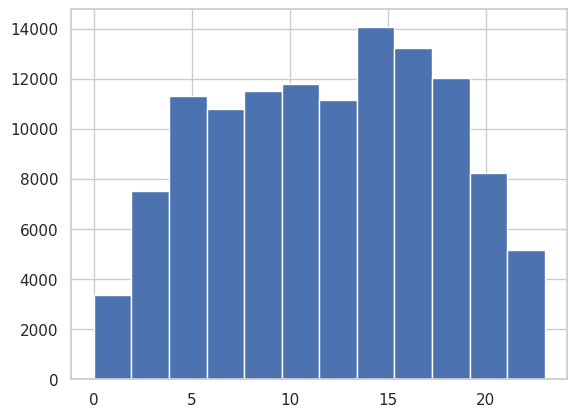

In [9]:
plt.hist(df['hour'], bins=12)

In [3]:
# 1. Parse as UTC
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'],
									   format="%Y-%m-%d %H:%M:%S UTC",
									   utc=True)

# 2. Convert to NYC time (this shifts the clock)
df['pickup_datetime'] = df['pickup_datetime'].dt.tz_convert("America/New_York")

# 3. Extract temporal features (NYC-local)
df['year'] = df['pickup_datetime'].dt.year
df['weekday'] = df['pickup_datetime'].dt.weekday
df['hour'] = df['pickup_datetime'].dt.hour
df['month'] = df['pickup_datetime'].dt.month

print("Temporal features extracted:")
print(f"  • Year: {df['year'].unique()}")
print(f"  • Month: {df['month'].unique()}")
print(f"  • Weekdays: 0 (Monday) to 6 (Sunday)")
print(f"  • Hours: 0 (midnight) to 23 (11 PM)")
print(f"\nSample of new features:")
df[['pickup_datetime', 'year', 'month', 'weekday', 'hour']].tail()

Temporal features extracted:
  • Year: [2010]
  • Month: [4]
  • Weekdays: 0 (Monday) to 6 (Sunday)
  • Hours: 0 (midnight) to 23 (11 PM)

Sample of new features:


,pickup_datetime,year,month,weekday,hour
119995,2010-04-18 10:33:03-04:00,2010,4,6,10
119996,2010-04-23 06:27:48-04:00,2010,4,4,6
119997,2010-04-18 14:50:40-04:00,2010,4,6,14
119998,2010-04-13 04:14:44-04:00,2010,4,1,4
119999,2010-04-17 12:00:14-04:00,2010,4,5,12


### <a id='toc2_2_'></a>[Calculating Distance](#toc0_)

Distance is likely the most important factor in determining taxi fare. We have pickup and dropoff coordinates (latitude and longitude), but we need to calculate the actual distance between these points.

We'll use the **Haversine formula**, which calculates the great-circle distance between two points on a sphere given their latitudes and longitudes. The formula is:

$$d = 2r \arcsin\left(\sqrt{\sin^2\left(\frac{\Delta\text{lat}}{2}\right) + \cos(\text{lat}_1) \cdot \cos(\text{lat}_2) \cdot \sin^2\left(\frac{\Delta\text{lon}}{2}\right)}\right)$$

Where $r$ is Earth's radius (approximately 3,959 ml or 6,371 km).

In [10]:
def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate the great circle distance in kilometers between two points
    on the earth (specified in decimal degrees).
    """
    # Convert from degrees to radians
    p =np.pi / 180.0 # 0.017453292519943295  # Pi/180


    # Haversine formula
    a = 0.5 - np.cos((lat2 - lat1) * p)/2 + \
        np.cos(lat1 * p) * np.cos(lat2 * p) * (1 - np.cos((lon2 - lon1) * p)) / 2

    # Distance in kilometers (Earth's radius ≈ 6,371 km, so 2*r = 12,742 km)
    distance_km = 12742 * np.arcsin(np.sqrt(a))

    return distance_km

In [11]:
# Calculate distance for all rides
df['distance'] = haversine_distance(df['pickup_latitude'],
								    df['pickup_longitude'],
									df['dropoff_latitude'],
									df['dropoff_longitude'])

print(f"Distance calculated for all {len(df)} rides.")
print(f"\nDistance Statistics:")
print(f"  Mean:   {df['distance'].mean():.2f} km")
print(f"  Median: {df['distance'].median():.2f} km")
print(f"  Min:    {df['distance'].min():.2f} km")
print(f"  Max:    {df['distance'].max():.2f} km")

Distance calculated for all 120000 rides.

Distance Statistics:
  Mean:   3.32 km
  Median: 2.24 km
  Min:    0.01 km
  Max:    28.85 km


#### Distance to Airports

In [13]:
def is_within_radius(lat,
                     lon,
                     center_lat,
                     center_lon,
                     radius_km=1.0):
    return haversine_distance(lat, lon, center_lat, center_lon) < radius_km

In [14]:
JFK = (40.6413, -73.7781)
LGA = (40.7769, -73.8740)


df["is_pickup_JFK"] = is_within_radius(df["pickup_latitude"],
									   df["pickup_longitude"],
									   *JFK) # * -> unpacking operator, as if
						#     is_within_radius(df["pickup_latitude"], df["pickup_longitude"],
						#     40.6413,
						#     -73.7781)

df["is_dropoff_JFK"] = is_within_radius(df["dropoff_latitude"],
										df["dropoff_longitude"],
										*JFK)

df["is_pickup_LGA"] = is_within_radius(df["pickup_latitude"],
									   df["pickup_longitude"],
									   *LGA)

df["is_dropoff_LGA"] = is_within_radius(df["dropoff_latitude"],
										df["dropoff_longitude"],
										*LGA)

### <a id='toc2_3_'></a>[Directional Vectors](#toc0_)

**Creating Directional Vector Features**

In addition to distance, the *direction* of travel might affect fares. We'll create vector features representing the change in latitude and longitude from pickup to dropoff:
- `lat_vec`: North-South movement (positive = northward)
- `lon_vec`: East-West movement (positive = eastward)

These capture geographic patterns that pure distance alone doesn't reveal (e.g., trips to/from airports, bridges with tolls).

In [15]:
df["lat_vec"] = df["dropoff_latitude"] - df["pickup_latitude"]
df["lon_vec"] = df["dropoff_longitude"] - df["pickup_longitude"]

### <a id='toc2_4_'></a>[Bearing](#toc0_)


Bearing represents the compass direction of travel from pickup to dropoff, measured in degrees (0° = North, 90° = East, 180° = South, 270° = West).

This feature captures directional patterns that might affect fares:
- Certain directions may have more traffic (e.g., rush hour flows)
- Bridge/tunnel crossings often follow specific bearings
- Airport routes typically have consistent directions

We use the standard geographic bearing formula that accounts for Earth's curvature.

In [16]:
def bearing(pickup_lat, pickup_lon, drop_lat, drop_lon):
    # convert to radians
    p_lat, p_lon = np.radians(pickup_lat), np.radians(pickup_lon)
    d_lat, d_lon = np.radians(drop_lat), np.radians(drop_lon)
    d_lon_delta = d_lon - p_lon

    x = np.sin(d_lon_delta) * np.cos(d_lat)
    y = (np.cos(p_lat) * np.sin(d_lat) -
         np.sin(p_lat) * np.cos(d_lat) * np.cos(d_lon_delta))

    brng = np.degrees(np.arctan2(x, y))
    return (brng + 360) % 360

df["bearing"] = bearing(df["pickup_latitude"],
						df["pickup_longitude"],
						df["dropoff_latitude"],
						df["dropoff_longitude"])

In [17]:
df["bearing"]

,bearing
0,41.930412
1,73.496003
2,59.639199
3,119.394631
4,82.094858
...,...
119995,202.464842
119996,231.481496
119997,202.529347
119998,54.996060


## <a id='toc3_'></a>[Data Cleaning](#toc0_)

Real-world data is messy. Before building our model, we need to clean the data by handling missing values, removing outliers, and dropping unnecessary columns. Proper data cleaning is crucial for building reliable predictive models.

### <a id='toc3_1_'></a>[Handling Missing Values](#toc0_)

In [ ]:
df.isnull().sum()

pickup_datetime      0
fare_amount          0
fare_class           0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
year                 0
weekday              0
hour                 0
month                0
distance             0
is_pickup_JFK        0
is_dropoff_JFK       0
is_pickup_LGA        0
is_dropoff_LGA       0
lat_vec              0
lon_vec              0
bearing              0
dtype: int64

In [18]:
# Remove rows with missing values (if any)
print(f"Shape before removing nulls: {df.shape}")
df = df.dropna()
print(f"Shape after removing nulls:  {df.shape}")
print(f"\nRows removed: {120000 - len(df)}")

Shape before removing nulls: (120000, 20)
Shape after removing nulls:  (120000, 20)

Rows removed: 0


### <a id='toc3_2_'></a>[Outlier Detection and Removal](#toc0_)

Outliers are extreme values that don't follow the general pattern of the data. They can significantly impact our linear regression model. Let's identify and remove outliers in our key variables: fare amount, distance, and coordinates.

**Why remove outliers?**
- Linear regression is sensitive to outliers (they heavily influence the fitted line)
- Outliers often represent data errors or exceptional cases
- Removing them can improve model performance on typical cases

**Methods for outlier detection:**
1. **Domain knowledge**: Use logical constraints (e.g., fares and distances must be positive)
2. **Visualization**: Identify extreme values through plots
3. **Statistical methods**: Use IQR (Interquartile Range) or Z-scores

<img src="./assets/IQR.png" width="600">

**Step 1: Remove logically impossible values**

In [19]:
print("Initial dataset size:", len(df))

# Remove negative or zero fares (impossible values)
print(f"\nRows with fare_amount <= 0: {len(df[df['fare_amount'] <= 0])}")
df = df[df['fare_amount'] > 0]

# Remove negative or extremely small distances (likely errors)
# NYC minimum fare applies even for very short trips, so distance should be meaningful
print(f"Rows with distance < 0.2 km: {len(df[df['distance'] < 0.2])}")
df = df[df['distance'] >= 0.2]

print(f"\nDataset size after removing impossible values: {len(df)}")
print(f"Rows removed: {120000 - len(df)}")

Initial dataset size: 120000

Rows with fare_amount <= 0: 0
Rows with distance < 0.2 km: 722

Dataset size after removing impossible values: 119278
Rows removed: 722


**Step 2: Statistical outlier detection using IQR method**

The IQR (Interquartile Range) method identifies outliers as values that fall below $Q1 - 1.5 \times IQR$ or above $Q3 + 1.5 \times IQR$, where:
- $Q1$ = 25th percentile (first quartile)
- $Q3$ = 75th percentile (third quartile)  
- $IQR = Q3 - Q1$ (interquartile range)

In [20]:
def remove_outliers_iqr(data, column, ratio=6):
    """Remove outliers using IQR method"""
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - ratio * IQR
    upper_bound = Q3 + ratio * IQR

    # Filter data
    filtered_data = data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]

    removed = len(data) - len(filtered_data)
    print(f"\n{column}:")
    print(f"  Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
    print(f"  Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
    print(f"  Outliers removed: {removed} ({removed/len(data)*100:.1f}%)")

    return filtered_data

print(f"Before outlier removal: {len(df)} rows")

# # Remove outliers from fare_amount
df = remove_outliers_iqr(df, 'fare_amount')

# Remove outliers from distance
df = remove_outliers_iqr(df, 'distance')


print(f"\nFinal dataset size: {len(df)} rows")
print(f"Total removed: {120000 - len(df)} rows ({(120000 - len(df))/120000*100:.1f}%)")

Before outlier removal: 119278 rows

fare_amount:
  Q1 = 5.70, Q3 = 11.30, IQR = 5.60
  Bounds: [-27.90, 44.90]
  Outliers removed: 1586 (1.3%)

distance:
  Q1 = 1.32, Q3 = 3.95, IQR = 2.63
  Bounds: [-14.46, 19.73]
  Outliers removed: 114 (0.1%)

Final dataset size: 117578 rows
Total removed: 2422 rows (2.0%)


### <a id='toc3_3_'></a>[Removing Unnecessary Columns](#toc0_)

We've already extracted useful features from `pickup_datetime` (year, weekday, hour), so we can drop the original column. We'll also drop `fare_class` as it's derived from fare_amount and shouldn't be used as a predictor.

In [21]:
# Drop unnecessary columns
columns_to_drop = ['pickup_datetime', 'fare_class']
df = df.drop(columns_to_drop, axis=1)

print(f"Dropped columns: {columns_to_drop}")
print(f"\nRemaining columns: {list(df.columns)}")
print(f"\nCleaned dataset shape: {df.shape}")

Dropped columns: ['pickup_datetime', 'fare_class']

Remaining columns: ['fare_amount', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count', 'year', 'weekday', 'hour', 'month', 'distance', 'is_pickup_JFK', 'is_dropoff_JFK', 'is_pickup_LGA', 'is_dropoff_LGA', 'lat_vec', 'lon_vec', 'bearing']

Cleaned dataset shape: (117578, 18)


In [22]:
# View the cleaned dataset
print("Cleaned Dataset Preview:")
print("="*70)
df.head(10)

Cleaned Dataset Preview:


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,year,weekday,hour,month,distance,is_pickup_JFK,is_dropoff_JFK,is_pickup_LGA,is_dropoff_LGA,lat_vec,lon_vec,bearing
0,6.5,-73.992365,40.730521,-73.975499,40.744746,1,2010,0,4,4,2.126312,False,False,False,False,0.014225,0.016866,41.930412
1,6.9,-73.990078,40.740558,-73.974232,40.744114,1,2010,5,11,4,1.392307,False,False,False,False,0.003556,0.015846,73.496003
2,10.1,-73.994149,40.751118,-73.960064,40.766235,2,2010,5,7,4,3.326763,False,False,False,False,0.015117,0.034085,59.639199
3,8.9,-73.990485,40.756422,-73.971205,40.748192,1,2010,6,17,4,1.864129,False,False,False,False,-0.008230,0.019280,119.394631
4,19.7,-73.990976,40.734202,-73.905956,40.743115,1,2010,4,22,4,7.231321,False,False,False,False,0.008913,0.085020,82.094858
5,8.1,-73.980481,40.748995,-73.983508,40.766459,1,2010,3,4,4,1.958574,False,False,False,False,0.017464,-0.003027,352.521295
6,4.9,-73.959535,40.779582,-73.947185,40.780223,1,2010,4,15,4,1.042304,False,False,False,False,0.000641,0.012350,86.074844
7,4.9,-74.002601,40.739419,-73.997912,40.730292,1,2010,3,5,4,1.089064,False,False,False,False,-0.009127,0.004689,158.728106
9,6.1,-73.977689,40.784175,-73.988639,40.778669,1,2010,4,14,4,1.106731,False,False,False,False,-0.005506,-0.010950,236.417017
10,7.3,-74.007913,40.740409,-73.985561,40.752076,1,2010,3,18,4,2.286620,False,False,False,False,0.011667,0.022352,55.427149


## <a id='toc4_'></a>[Data Visualization](#toc0_)

Visualization helps us understand patterns in the data and validate our cleaning steps. Let's explore the geographic distribution, temporal patterns, and relationships between features.

### <a id='toc4_1_'></a>[Geospatial Analysis](#toc0_)

Let's visualize where taxis are picking up and dropping off passengers in NYC. This helps us understand the geographic distribution of rides and identify hotspots.

In [ ]:
# conda install -c conda-forge nbformat
# !pip install --upgrade nbformat

In [23]:
# Pickup locations map
fig_pickup = px.scatter_map(df,
							lat='pickup_latitude',
							lon='pickup_longitude',
							hover_name='fare_amount',
							hover_data=['fare_amount', 'distance'],
							color='fare_amount',
							color_continuous_scale=px.colors.sequential.Agsunset,
							opacity=0.05,
							center={'lat': 40.75, 'lon': -73.97},
							zoom=11,
							height=500,
							width=1000,
							map_style="carto-positron",
							title="Taxi Pickup Locations in NYC (colored by fare amount)")

fig_pickup.update_layout(margin={"r": 0, "t": 40, "l": 0, "b": 0})
fig_pickup.show()

In [24]:
# Dropoff locations map
fig_dropoff = px.scatter_map(df,
							 lat='dropoff_latitude',
							 lon='dropoff_longitude',
							 hover_name='fare_amount',
							 hover_data=['fare_amount', 'distance'],
							 color='fare_amount',
							 color_continuous_scale=px.colors.sequential.Plasma_r,
							 opacity=0.1,
							 center={'lat': 40.75, 'lon': -73.97},
							 zoom=11,
							 height=500,
							 width=1000,
							 map_style="carto-positron",
							 title="Taxi Dropoff Locations in NYC (colored by fare amount)")

fig_dropoff.update_layout(margin={"r": 0, "t": 40, "l": 0, "b": 0})
fig_dropoff.show()

### <a id='toc4_2_'></a>[Fare Distribution](#toc0_)

Understanding the distribution of fare amounts helps us know what to expect from our predictions. Most rides should cluster around typical fare values.

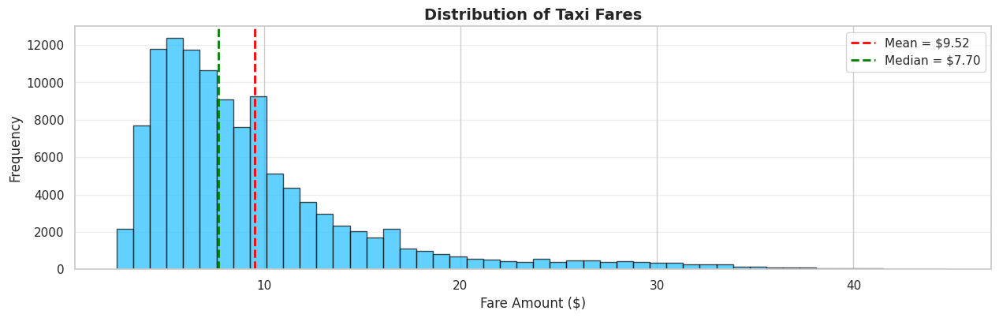

Fare Statistics:
  Mean:   $9.52
  Median: $7.70
  Std:    $6.02


In [25]:
plt.figure(figsize=(15, 4))

plt.hist(df['fare_amount'], bins=50, color='#20beff', edgecolor='black', alpha=0.7)
plt.xlabel("Fare Amount ($)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.title("Distribution of Taxi Fares", fontsize=14, fontweight='bold')
plt.axvline(df['fare_amount'].mean(), color='red', linestyle='--',
            linewidth=2, label=f"Mean = ${df['fare_amount'].mean():.2f}")
plt.axvline(df['fare_amount'].median(), color='green', linestyle='--',
            linewidth=2, label=f"Median = ${df['fare_amount'].median():.2f}")
plt.legend()
plt.grid(True, alpha=0.3, axis='y')
plt.show()

print(f"Fare Statistics:")
print(f"  Mean:   ${df['fare_amount'].mean():.2f}")
print(f"  Median: ${df['fare_amount'].median():.2f}")
print(f"  Std:    ${df['fare_amount'].std():.2f}")

### <a id='toc4_3_'></a>[Temporal Patterns](#toc0_)

Taxi demand varies by time of day and day of week. Let's explore these temporal patterns to understand when people take taxis most frequently.

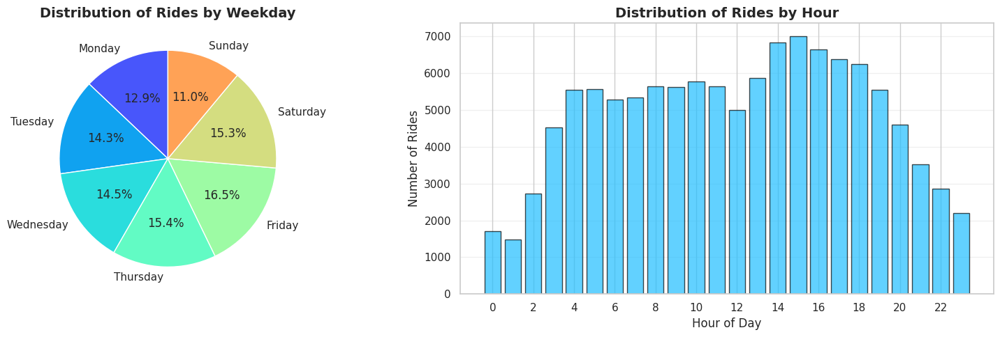

Peak hours:
  15:00 - 7,006 rides
  14:00 - 6,835 rides
  16:00 - 6,635 rides


In [26]:
# Weekday distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Pie chart for weekdays
days_list = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_counts = df['weekday'].value_counts().sort_index()

axes[0].pie(weekday_counts.values, labels=days_list, autopct="%.1f%%",
            colors=palette, startangle=90)
axes[0].set_title("Distribution of Rides by Weekday", fontsize=14, fontweight='bold')

# Bar chart for hours
hour_counts = df['hour'].value_counts().sort_index()
axes[1].bar(hour_counts.index, hour_counts.values, color='#20beff', edgecolor='black', alpha=0.7)
axes[1].set_xlabel("Hour of Day", fontsize=12)
axes[1].set_ylabel("Number of Rides", fontsize=12)
axes[1].set_title("Distribution of Rides by Hour", fontsize=14, fontweight='bold')
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("Peak hours:")
top_hours = hour_counts.nlargest(3)
for hour, count in top_hours.items():
    print(f"  {hour}:00 - {count:,} rides")

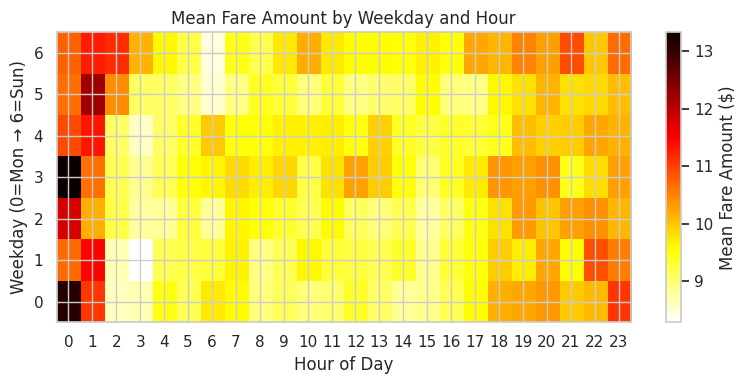

In [28]:
# Compute mean fares by weekday x hour
pivot = df.pivot_table(index="weekday",
					   columns="hour",
					   values="fare_amount",
					   aggfunc="mean")

plt.figure(figsize=(8, 4))

plt.imshow( pivot,
			aspect='auto',
			origin='lower',
			cmap='hot_r')

plt.colorbar(label='Mean Fare Amount ($)')
plt.xlabel("Hour of Day")
plt.ylabel("Weekday (0=Mon → 6=Sun)")
plt.title("Mean Fare Amount by Weekday and Hour")

# Tick labels
plt.xticks(range(24), range(24))
plt.yticks(range(7), range(7))

plt.tight_layout()
plt.show()


In [30]:
# Binary indicator for weekend (assuming week_day: 0=Mon, ..., 5=Sat, 6=Sun)
df['is_weekend'] = df['weekday'].isin([5, 6]).astype(int)

# Binary indicator for rush hour (7-9 or 16-18, but only on weekdays)
df['is_rush_hour'] = ((~df['weekday'].isin([5, 6])) &  # Weekdays only
                      (df['hour'].between(7, 9) | df['hour'].between(16, 18))).astype(int)

# Binary indicator for night owl hours
df['is_night_owl'] = ((df['hour'] >= 23) | (df['hour'] <= 2)).astype(int)

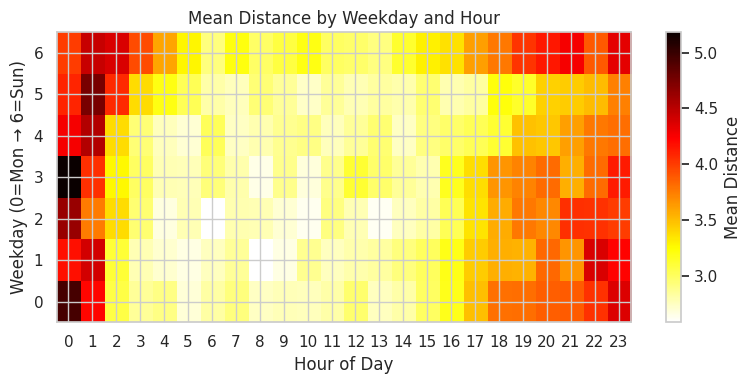

In [32]:
# Compute mean fares by weekday x hour
pivot = df.pivot_table(index="weekday",
					   columns="hour",
					   values="distance",
					   aggfunc="mean")

plt.figure(figsize=(8, 4))

plt.imshow(pivot,
		   aspect='auto',
		   origin='lower',cmap='hot_r')

plt.colorbar(label='Mean Distance')
plt.xlabel("Hour of Day")
plt.ylabel("Weekday (0=Mon → 6=Sun)")
plt.title("Mean Distance by Weekday and Hour")

# Tick labels
plt.xticks(range(24), range(24))
plt.yticks(range(7), range(7))

plt.tight_layout()
plt.show()


In [33]:
# Compute mean fare_amount by each binary group
mean_by_weekend = df.groupby('is_weekend')['fare_amount'].mean()
mean_by_rush = df.groupby('is_rush_hour')['fare_amount'].mean()
mean_by_night_owl = df.groupby('is_night_owl')['fare_amount'].mean()

# Print results for inspection
print("Mean fare by is_weekend:\n", mean_by_weekend)
print("\nMean fare by is_rush_hour:\n", mean_by_rush)
print("\nMean fare by is_night_owl:\n", mean_by_night_owl)


Mean fare by is_weekend:
 is_weekend
0    9.494655
1    9.580198
Name: fare_amount, dtype: float64

Mean fare by is_rush_hour:
 is_rush_hour
0    9.514305
1    9.527415
Name: fare_amount, dtype: float64

Mean fare by is_night_owl:
 is_night_owl
0     9.458144
1    10.312468
Name: fare_amount, dtype: float64


### <a id='toc4_4_'></a>[Distance Analysis](#toc0_)

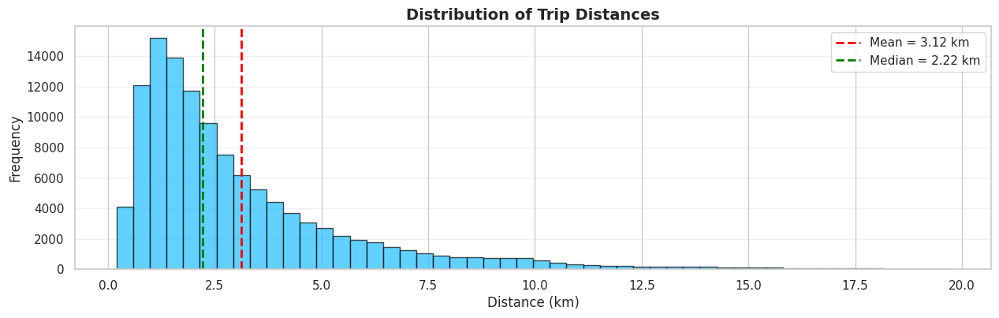

Most taxi rides are relatively short distances.


In [34]:
plt.figure(figsize=(15, 4))

df['distance'].hist(bins=50, color='#20beff', edgecolor='black', alpha=0.7)
plt.xlabel("Distance (km)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.title("Distribution of Trip Distances", fontsize=14, fontweight='bold')
plt.axvline(df['distance'].mean(), color='red', linestyle='--',
            linewidth=2, label=f"Mean = {df['distance'].mean():.2f} km")
plt.axvline(df['distance'].median(), color='green', linestyle='--',
            linewidth=2, label=f"Median = {df['distance'].median():.2f} km")
plt.legend()
plt.grid(True, alpha=0.3, axis='y')
plt.show()

print("Most taxi rides are relatively short distances.")

### <a id='toc4_5_'></a>[Fare vs Distance Relationship](#toc0_)

This is the most important visualization - it shows the relationship between our primary predictor (distance) and target variable (fare). If the relationship is roughly linear, linear regression is appropriate.

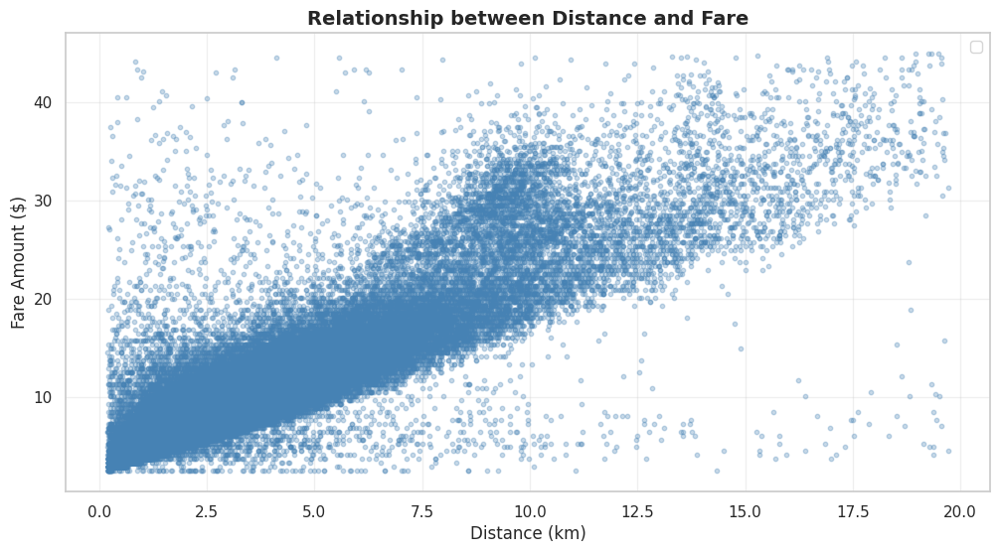


Average fare per km: $3.05


In [35]:
plt.figure(figsize=(12, 6))

# Scatter plot with transparency
plt.scatter(df['distance'], df['fare_amount'], alpha=0.3, s=10, color='steelblue')
plt.xlabel("Distance (km)", fontsize=12)
plt.ylabel("Fare Amount ($)", fontsize=12)
plt.title("Relationship between Distance and Fare", fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)

plt.legend()
plt.show()

# Calculate average fare per km
avg_fare_per_km = df['fare_amount'].sum() / df['distance'].sum()
print(f"\nAverage fare per km: ${avg_fare_per_km:.2f}")

In [36]:
# Analyze fare by passenger count
passenger_analysis = df.groupby('passenger_count').agg({
    'fare_amount': 'mean',
    'distance': 'mean'
}).round(2)

print("Average Fare and Distance by Passenger Count:")
print(passenger_analysis)

Average Fare and Distance by Passenger Count:
                 fare_amount  distance
passenger_count                       
1                       9.40      3.09
2                       9.98      3.25
3                       9.79      3.13
4                       9.79      3.10
5                       9.94      3.33


### <a id='toc4_6_'></a>[Correlation Analysis](#toc0_)

Let's examine the correlations between all numerical features to understand their relationships. This helps identify:
- Which features are strongly correlated with our target (fare_amount)
- Which features are correlated with each other (potential multicollinearity)
- Whether we should keep or drop certain features

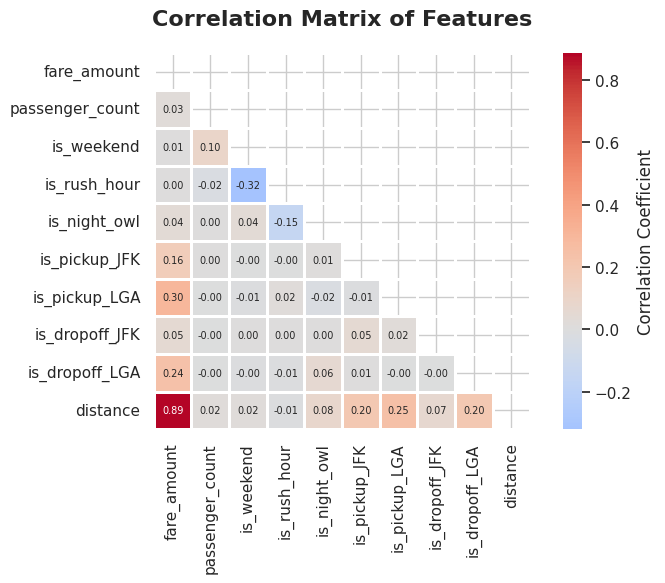

In [42]:
# Select numerical columns for correlation analysis (excluding year - only one value)
numerical_cols = ['fare_amount', 'passenger_count',
                  'is_weekend', 'is_rush_hour','is_night_owl',
                  'is_pickup_JFK', 'is_pickup_LGA', 'is_dropoff_JFK', 'is_dropoff_LGA',
                   'distance']

# Calculate correlation matrix
correlation_matrix = df[numerical_cols].corr()

# Create a large figure for better readability
plt.figure(figsize=(8, 6))

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# Create heatmap
sns.heatmap(correlation_matrix,
            mask=mask,
            annot=True,          # Show correlation values
            cmap='coolwarm',     # Color scheme (red=positive, blue=negative)
            center=0,            # Center colormap at 0
            fmt='.2f',           # Format to 2 decimal places
            square=True,         # Make cells square-shaped
            linewidths=1,        # Add gridlines
            annot_kws={"size": 7},        # Font size
            cbar_kws={'label': 'Correlation Coefficient'})

plt.title('Correlation Matrix of Features', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

## <a id='toc5_'></a>[Model Building](#toc0_)

Now that we've cleaned and explored our data, let's build a linear regression model to predict taxi fares. We'll select relevant features, split the data into training and test sets, and train our model.

### <a id='toc5_1_'></a>[Feature Selection](#toc0_)

We'll use the features we engineered (year, weekday, hour, distance, passenger_count) to predict fare_amount. We won't use the raw coordinates as features since we've already extracted distance from them.

In [43]:
# Select features for the model
feature_columns = ['is_night_owl',
				   'passenger_count',
				   'is_pickup_JFK',
				   'is_pickup_LGA',
				   'is_dropoff_JFK',
				   'is_dropoff_LGA',
				   'bearing',
				   'lat_vec',
				   'lon_vec',
				   'distance']

target_column = 'fare_amount'

X = df[feature_columns]
y = df[target_column]

print("Features (X):")
print(f"  Columns: {list(X.columns)}")
print(f"  Shape: {X.shape}")
print(f"\nTarget (y):")
print(f"  Column: {target_column}")
print(f"  Shape: {y.shape}")
print(f"\nFirst few samples:")
print(X.head())

Features (X):
  Columns: ['is_night_owl', 'passenger_count', 'is_pickup_JFK', 'is_pickup_LGA', 'is_dropoff_JFK', 'is_dropoff_LGA', 'bearing', 'lat_vec', 'lon_vec', 'distance']
  Shape: (117578, 10)

Target (y):
  Column: fare_amount
  Shape: (117578,)

First few samples:
   is_night_owl  passenger_count  is_pickup_JFK  is_pickup_LGA  \
0             0                1          False          False   
1             0                1          False          False   
2             0                2          False          False   
3             0                1          False          False   
4             0                1          False          False   

   is_dropoff_JFK  is_dropoff_LGA     bearing   lat_vec   lon_vec  distance  
0           False           False   41.930412  0.014225  0.016866  2.126312  
1           False           False   73.496003  0.003556  0.015846  1.392307  
2           False           False   59.639199  0.015117  0.034085  3.326763  
3           False  

### <a id='toc5_2_'></a>[Train-Test Split](#toc0_)

We split our data into training (80%) and test (20%) sets. The training set is used to fit the model, while the test set evaluates its performance on unseen data. This helps us assess how well the model will generalize to new taxi rides.

In [44]:
from sklearn.model_selection import train_test_split

# Split data: 80% training, 20% test
X_train, X_test, y_train, y_test = train_test_split(X,
													y,
													test_size=0.2,
													random_state=42)

print("Data Split Summary:")
print("="*50)
print(f"Training set: {len(X_train):,} samples ({len(X_train)/len(X)*100:.1f}%)")
print(f"Test set:     {len(X_test):,} samples ({len(X_test)/len(X)*100:.1f}%)")
print(f"\nTotal:        {len(X):,} samples")

Data Split Summary:
Training set: 94,062 samples (80.0%)
Test set:     23,516 samples (20.0%)

Total:        117,578 samples


### <a id='toc5_3_'></a>[Model Training](#toc0_)

We'll use a **Pipeline** that combines feature scaling with linear regression. This is a powerful tool that chains multiple steps together into a single workflow.

**What is a Pipeline?**

A Pipeline sequentially applies transformations followed by a final model. Think of it as an assembly line: Raw Features → Scaler → Model → Predictions.

Key benefits:
- **Cleaner code**: Bundle preprocessing and modeling into one object
- **Prevents data leakage**: Transformations are fit only on training data
- **Easier deployment**: The entire workflow is encapsulated in one model

<img src="./assets/pipeline.png" width="800">


**Why use StandardScaler?**

StandardScaler standardizes features using: $z = \frac{x - \mu}{\sigma}$ where $\mu$ is mean and $\sigma$ is standard deviation.

Our features are on different scales:
- `distance`: 0.2 to 20+ km
- `hour`: 0 to 23  
- `weekday`: 0 to 6
- `passenger_count`: 1 to 5

Without scaling, distance (with large values) would dominate the model simply because its numbers are bigger, not because it's more important.

With scaling, all features are transformed to have mean = 0 and std = 1, allowing the model to fairly weigh each feature's importance based on actual predictive power, not numerical scale.

In [45]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures


model = Pipeline([
    ("poly", PolynomialFeatures(degree=3 , include_bias=False)),
    ("scaler", StandardScaler()),
    # ("regressor", LinearRegression())
    ("regressor", Ridge(alpha=100))
])

model.fit(X_train, y_train)


# Train the model
print("Training the model...")
model.fit(X_train, y_train)
print("✓ Model training complete!")

# Display model coefficients
coefficients = model.named_steps['regressor'].coef_
intercept = model.named_steps['regressor'].intercept_

print(f"\nModel Coefficients:")
print("="*50)
for feature, coef in zip(feature_columns, coefficients):
    print(f"  {feature:20s}: {coef:10.4f}")
print(f"  {'Intercept':20s}: {intercept:10.4f}")

Training the model...
✓ Model training complete!

Model Coefficients:
  is_night_owl        :    -0.0359
  passenger_count     :    -0.0037
  is_pickup_JFK       :     0.1395
  is_pickup_LGA       :     0.0393
  is_dropoff_JFK      :     0.0750
  is_dropoff_LGA      :    -0.0340
  bearing             :     0.1590
  lat_vec             :    -0.0346
  lon_vec             :     0.5241
  distance            :     4.4067
  Intercept           :     9.5169


In [46]:
coefs = model.named_steps['regressor'].coef_ # individual steps
inter  = model.named_steps['regressor'].intercept_

print("\nModel Coefficients")
print("="*50)

for i, c in enumerate(coefs):
    print(f"coef[{i:2d}]: {c:10.4f}")

print(f"{'Intercept':10s}: {inter:10.4f}")



Model Coefficients
coef[ 0]:    -0.0359
coef[ 1]:    -0.0037
coef[ 2]:     0.1395
coef[ 3]:     0.0393
coef[ 4]:     0.0750
coef[ 5]:    -0.0340
coef[ 6]:     0.1590
coef[ 7]:    -0.0346
coef[ 8]:     0.5241
coef[ 9]:     4.4067
coef[10]:    -0.0359
coef[11]:     0.0545
coef[12]:     0.0095
coef[13]:     0.0194
coef[14]:    -0.0554
coef[15]:     0.0554
coef[16]:     0.0117
coef[17]:    -0.0593
coef[18]:    -0.0689
coef[19]:    -0.0926
coef[20]:     0.0281
coef[21]:    -0.1505
coef[22]:     0.1836
coef[23]:    -0.1058
coef[24]:     0.1165
coef[25]:     0.0818
coef[26]:    -0.3481
coef[27]:    -0.1734
coef[28]:     0.9444
coef[29]:     0.1395
coef[30]:     0.0000
coef[31]:    -0.0058
coef[32]:     0.0067
coef[33]:    -0.0648
coef[34]:    -0.0706
coef[35]:     0.3335
coef[36]:    -0.2444
coef[37]:     0.0393
coef[38]:    -0.0143
coef[39]:     0.0595
coef[40]:    -0.0261
coef[41]:     0.2940
coef[42]:    -0.1258
coef[43]:    -0.1251
coef[44]:     0.0750
coef[45]:     0.0000
coef[46]:     

## <a id='toc6_'></a>[Model Evaluation](#toc0_)

Model evaluation is crucial to understand how well our model performs and where it might fail. We'll use multiple metrics and diagnostic tools to thoroughly assess our taxi fare prediction model. Remember: **no single metric tells the whole story**.

### <a id='toc6_1_'></a>[Error-Based Metrics (MSE, RMSE, MAE)](#toc0_)

Error metrics quantify how far our predictions are from actual values:

- **MSE** (Mean Squared Error): Average of squared errors - penalizes large errors heavily
- **RMSE** (Root Mean Squared Error): Square root of MSE - same units as target variable
- **MAE** (Mean Absolute Error): Average of absolute errors - robust to outliers

These metrics help us understand typical prediction errors in dollar terms.

In [47]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Make predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Calculate metrics for both train and test sets
train_mse = mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)
train_mae = mean_absolute_error(y_train, y_train_pred)

test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(y_test, y_test_pred)

print("="*70)
print("ERROR-BASED METRICS")
print("="*70)
print(f"\n{'Metric':<20} {'Training Set':>20} {'Test Set':>20}")
print("-"*70)
print(f"{'MSE':<20} ${train_mse:>19,.2f} ${test_mse:>19,.2f}")
print(f"{'RMSE':<20} ${train_rmse:>19,.2f} ${test_rmse:>19,.2f}")
print(f"{'MAE':<20} ${train_mae:>19,.2f} ${test_mae:>19,.2f}")
print("-"*70)

print(f"\n📊 Interpretation:")
print(f"  • On average, predictions are off by ${test_rmse:.2f} (RMSE)")
print(f"  • Typical absolute error is ${test_mae:.2f} (MAE)")
print(f"  • RMSE/MAE ratio: {test_rmse/test_mae:.2f}", end="")
if test_rmse/test_mae > 1.5:
    print(" → Some large errors exist (potential outliers)")
else:
    print(" → Errors are relatively uniform")

ERROR-BASED METRICS

Metric                       Training Set             Test Set
----------------------------------------------------------------------
MSE                  $               6.16 $               6.15
RMSE                 $               2.48 $               2.48
MAE                  $               1.44 $               1.45
----------------------------------------------------------------------

📊 Interpretation:
  • On average, predictions are off by $2.48 (RMSE)
  • Typical absolute error is $1.45 (MAE)
  • RMSE/MAE ratio: 1.71 → Some large errors exist (potential outliers)


### <a id='toc6_2_'></a>[Goodness-of-Fit (R-squared)](#toc0_)

R-squared (R²) tells us what proportion of variance in fare amounts is explained by our model. It ranges from 0 to 1 (or negative for very poor models):

$$R^2 = 1 - \frac{\sum(y_i - \hat{y}_i)^2}{\sum(y_i - \bar{y})^2}$$

Where:
- **R² = 1**: Perfect predictions
- **R² = 0.7**: Model explains 70% of variance
- **R² = 0**: Model no better than predicting the mean

In [48]:
# Calculate R-squared
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("="*70)
print("R-SQUARED (COEFFICIENT OF DETERMINATION)")
print("="*70)
print(f"\nTraining R²: {train_r2:.4f} ({train_r2*100:.2f}% variance explained)")
print(f"Test R²:     {test_r2:.4f} ({test_r2*100:.2f}% variance explained)")

# Check for overfitting
r2_diff = train_r2 - test_r2
print(f"\nDifference:  {r2_diff:.4f}", end="")
if r2_diff > 0.1:
    print(" ⚠️  Possible overfitting (train >> test)")
elif r2_diff < -0.05:
    print(" ⚠️  Unusual (test > train)")
else:
    print(" ✓ Good generalization")

print(f"\n📊 Interpretation:")
print(f"  • Our model explains {test_r2*100:.1f}% of fare variation")
print(f"  • Remaining {(1-test_r2)*100:.1f}% is due to factors not in our model")
print(f"  • (e.g., traffic conditions, route choice, tolls)")

R-SQUARED (COEFFICIENT OF DETERMINATION)

Training R²: 0.8299 (82.99% variance explained)
Test R²:     0.8315 (83.15% variance explained)

Difference:  -0.0015 ✓ Good generalization

📊 Interpretation:
  • Our model explains 83.1% of fare variation
  • Remaining 16.9% is due to factors not in our model
  • (e.g., traffic conditions, route choice, tolls)


### <a id='toc6_3_'></a>[Residual Analysis](#toc0_)

Residual analysis examines prediction errors to validate model assumptions. **Residual** = Actual - Predicted. For a good linear regression model, residuals should be:

1. **Randomly distributed** around zero (no patterns)
2. **Normally distributed** (bell-shaped histogram)
3. **Homoscedastic** (constant variance across predictions)
4. **Independent** (no autocorrelation)

Violations of these assumptions suggest the model might be inappropriate or improvable.

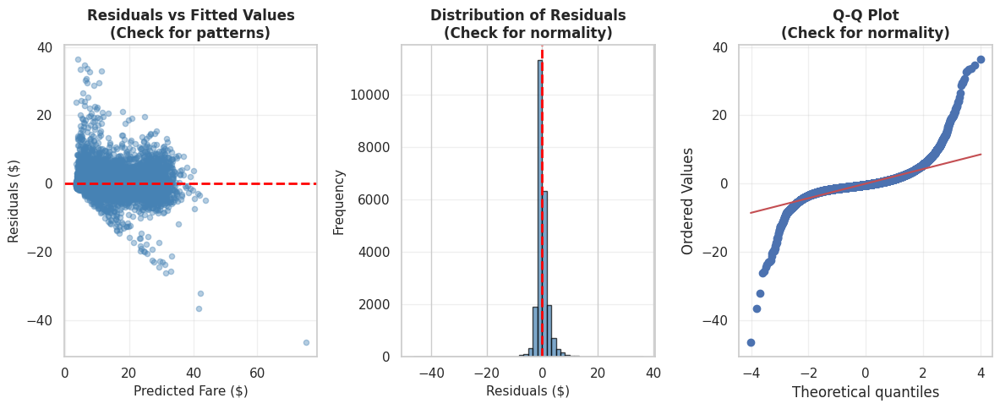

In [49]:
# Calculate residuals
residuals_train = y_train - y_train_pred
residuals_test = y_test - y_test_pred

# Create comprehensive residual diagnostic plots
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

# Plot 1: Residuals vs Fitted (Test Set)
axes[0].scatter(y_test_pred, residuals_test, alpha=0.4, s=20, color='steelblue')
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0].set_xlabel('Predicted Fare ($)', fontsize=11)
axes[0].set_ylabel('Residuals ($)', fontsize=11)
axes[0].set_title('Residuals vs Fitted Values\n(Check for patterns)', fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Plot 2: Histogram of Residuals
axes[1].hist(residuals_test, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel('Residuals ($)', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].set_title('Distribution of Residuals\n(Check for normality)', fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

# Plot 3: Q-Q Plot
from scipy import stats
stats.probplot(residuals_test, dist="norm", plot=axes[2])
axes[2].set_title('Q-Q Plot\n(Check for normality)', fontweight='bold')
axes[2].grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

### <a id='toc6_4_'></a>[Prediction Visualization](#toc0_)

Let's visualize how well our predictions match the actual fares. Perfect predictions would lie on the diagonal line (predicted = actual).

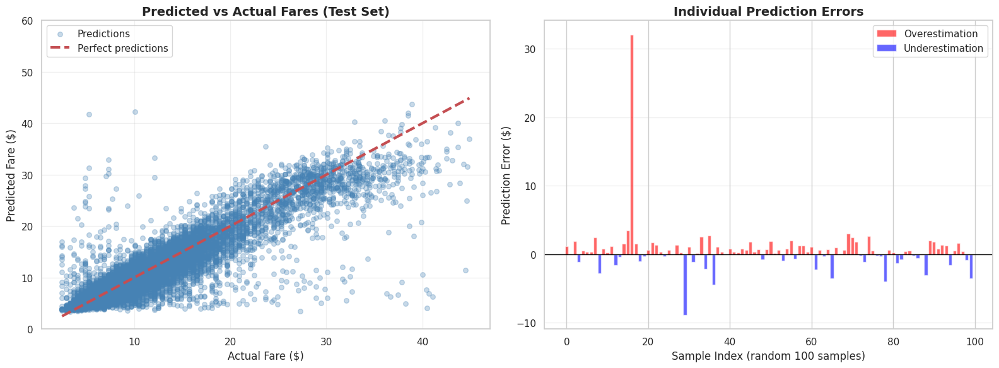


Prediction Accuracy Summary:
  52.2% of predictions within ±$1.00
  80.9% of predictions within ±$2.00
  96.2% of predictions within ±$5.00


In [50]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Predictions vs Actual (Test Set)
axes[0].scatter(y_test, y_test_pred, alpha=0.3, s=30, color='steelblue', label='Predictions')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
             'r--', lw=3, label='Perfect predictions')
axes[0].set_xlabel('Actual Fare ($)', fontsize=12)
axes[0].set_ylabel('Predicted Fare ($)', fontsize=12)
axes[0].set_title('Predicted vs Actual Fares (Test Set)', fontsize=14, fontweight='bold')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0, 60])

# Plot 2: Prediction Errors
errors = y_test_pred - y_test.values
colors = ['red' if e > 0 else 'blue' for e in errors]
sample_indices = np.random.choice(len(errors), size=min(100, len(errors)), replace=False)
axes[1].bar(range(len(sample_indices)), errors[sample_indices], alpha=0.6, color=np.array(colors)[sample_indices])
axes[1].axhline(y=0, color='black', linestyle='-', linewidth=1)
axes[1].set_xlabel('Sample Index (random 100 samples)', fontsize=12)
axes[1].set_ylabel('Prediction Error ($)', fontsize=12)
axes[1].set_title('Individual Prediction Errors', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

# Add legend for colors
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='red', alpha=0.6, label='Overestimation'),
                   Patch(facecolor='blue', alpha=0.6, label='Underestimation')]
axes[1].legend(handles=legend_elements)

plt.tight_layout()
plt.show()

# Calculate percentage of predictions within certain error bounds
within_1 = np.sum(np.abs(errors) <= 1) / len(errors) * 100
within_2 = np.sum(np.abs(errors) <= 2) / len(errors) * 100
within_5 = np.sum(np.abs(errors) <= 5) / len(errors) * 100

print(f"\nPrediction Accuracy Summary:")
print(f"  {within_1:.1f}% of predictions within ±$1.00")
print(f"  {within_2:.1f}% of predictions within ±$2.00")
print(f"  {within_5:.1f}% of predictions within ±$5.00")

### <a id='toc6_5_'></a>[Cross-Validation](#toc0_)

Cross-validation provides a more robust estimate of model performance by training and evaluating on multiple different splits of the data. Instead of a single train-test split, we use **k-fold cross-validation**:

1. Split data into k equal parts (folds)
2. Train on k-1 folds, test on the remaining fold
3. Repeat k times, each time using a different fold as the test set
4. Average the k performance scores

This gives us:
- **More reliable performance estimates** (less dependent on a single split)
- **Confidence intervals** for our metrics
- **Detection of high variance** (if scores vary widely across folds)

<img src="./assets/kfold.png" width="600">

In [51]:
from sklearn.model_selection import cross_validate

k = 10
cv_results = cross_validate(
    model, X, y,
    cv=k,
    scoring=['r2', 'neg_mean_squared_error', 'neg_mean_absolute_error'],
    return_train_score=True
)

# Train metrics
r2_train = cv_results['train_r2']
mse_train = -cv_results['train_neg_mean_squared_error']
rmse_train = np.sqrt(mse_train)
mae_train = -cv_results['train_neg_mean_absolute_error']

# Test metrics
r2_test = cv_results['test_r2']
mse_test = -cv_results['test_neg_mean_squared_error']
rmse_test = np.sqrt(mse_test)
mae_test = -cv_results['test_neg_mean_absolute_error']

print("="*70)
print(f"CROSS-VALIDATION RESULTS ({k}-Fold)")
print("="*70)
print(f"\n{'Metric':<20} {'Train (mean±std)':>25} {'Test (mean±std)':>25}")
print("-"*70)

print(f"{'R²':<20} "
      f"{r2_train.mean():>10.4f} ± {r2_train.std():<10.4f}"
      f"{r2_test.mean():>10.4f} ± {r2_test.std():<10.4f}")

print(f"{'MSE':<20} "
      f"{mse_train.mean():>10.4f} ± {mse_train.std():<10.4f}"
      f"{mse_test.mean():>10.4f} ± {mse_test.std():<10.4f}")

print(f"{'RMSE':<20} "
      f"{rmse_train.mean():>10.4f} ± {rmse_train.std():<10.4f}"
      f"{rmse_test.mean():>10.4f} ± {rmse_test.std():<10.4f}")

print(f"{'MAE':<20} "
      f"{mae_train.mean():>10.4f} ± {mae_train.std():<10.4f}"
      f"{mae_test.mean():>10.4f} ± {mae_test.std():<10.4f}")

print("-"*70)


CROSS-VALIDATION RESULTS (10-Fold)

Metric                        Train (mean±std)           Test (mean±std)
----------------------------------------------------------------------
R²                       0.8313 ± 0.0006        0.8270 ± 0.0070    
MSE                      6.1138 ± 0.0190        6.2693 ± 0.2421    
RMSE                     2.4726 ± 0.0038        2.5034 ± 0.0482    
MAE                      1.4436 ± 0.0019        1.4507 ± 0.0152    
----------------------------------------------------------------------


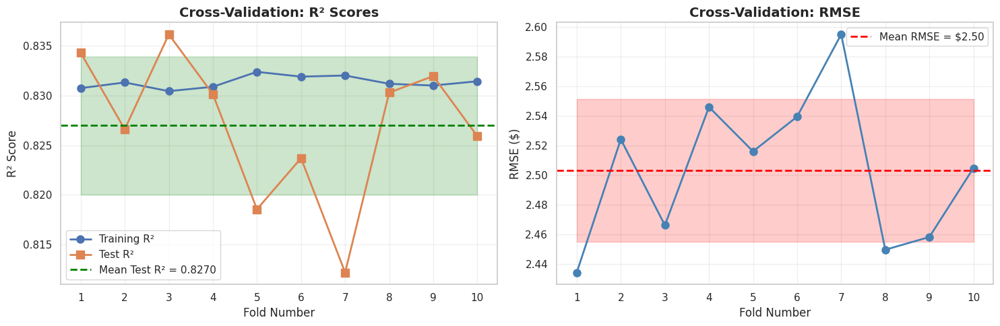


✓ Consistent scores across all folds indicate stable model performance


In [52]:
# Visualize cross-validation results
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: R² scores across folds
folds = np.arange(1, k+1)
axes[0].plot(folds, r2_train, 'o-', label='Training R²', linewidth=2, markersize=8)
axes[0].plot(folds, r2_test, 's-', label='Test R²', linewidth=2, markersize=8)
axes[0].axhline(r2_test.mean(), color='green', linestyle='--',
                label=f'Mean Test R² = {r2_test.mean():.4f}', linewidth=2)
axes[0].fill_between(folds,
                      r2_test.mean() - r2_test.std(),
                      r2_test.mean() + r2_test.std(),
                      alpha=0.2, color='green')
axes[0].set_xlabel('Fold Number', fontsize=12)
axes[0].set_ylabel('R² Score', fontsize=12)
axes[0].set_title('Cross-Validation: R² Scores', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_xticks(folds)

# Plot 2: RMSE scores across folds
axes[1].plot(folds, rmse_test, 'o-', color='steelblue', linewidth=2, markersize=8)
axes[1].axhline(rmse_test.mean(), color='red', linestyle='--',
                label=f'Mean RMSE = ${rmse_test.mean():.2f}', linewidth=2)
axes[1].fill_between(folds,
                      rmse_test.mean() - rmse_test.std(),
                      rmse_test.mean() + rmse_test.std(),
                      alpha=0.2, color='red')
axes[1].set_xlabel('Fold Number', fontsize=12)
axes[1].set_ylabel('RMSE ($)', fontsize=12)
axes[1].set_title('Cross-Validation: RMSE', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_xticks(folds)

plt.tight_layout()
plt.show()

print("\n✓ Consistent scores across all folds indicate stable model performance")

In [53]:
# Final Model Summary
print("="*70)
print("FINAL MODEL SUMMARY")
print("="*70)
print(f"\n📊 Dataset:")
print(f"  Original size:     120,000 rides")
print(f"  After cleaning:    {len(df):,} rides ({len(df)/120000*100:.1f}%)")
print(f"  Training samples:  {len(X_train):,}")
print(f"  Test samples:      {len(X_test):,}")

print(f"\n🎯 Model Performance (Test Set):")
print(f"  R² Score:          {test_r2:.4f} ({test_r2*100:.2f}% variance explained)")
print(f"  RMSE:              ${test_rmse:.2f}")
print(f"  MAE:               ${test_mae:.2f}")

print(f"\n🔄 Cross-Validation (5-Fold):")
print(f"  R² Score:          {r2_test.mean():.4f} ± {r2_test.std():.4f}")
print(f"  RMSE:              ${rmse_test.mean():.2f} ± ${rmse_test.std():.2f}")

print(f"\n📈 Key Features (by coefficient magnitude after scaling):")
feature_importance = list(zip(feature_columns, np.abs(coefficients)))
feature_importance.sort(key=lambda x: x[1], reverse=True)
for i, (feature, coef) in enumerate(feature_importance, 1):
    print(f"  {i}. {feature:20s}: {coef:.4f}")

print(f"\n💡 Practical Interpretation:")
print(f"  • Typical prediction error: ~${test_mae:.2f}")
print(f"  • {within_5:.1f}% of predictions within ±$5")
print("="*70)

FINAL MODEL SUMMARY

📊 Dataset:
  Original size:     120,000 rides
  After cleaning:    117,578 rides (98.0%)
  Training samples:  94,062
  Test samples:      23,516

🎯 Model Performance (Test Set):
  R² Score:          0.8315 (83.15% variance explained)
  RMSE:              $2.48
  MAE:               $1.45

🔄 Cross-Validation (5-Fold):
  R² Score:          0.8270 ± 0.0070
  RMSE:              $2.50 ± $0.05

📈 Key Features (by coefficient magnitude after scaling):
  1. distance            : 4.4067
  2. lon_vec             : 0.5241
  3. bearing             : 0.1590
  4. is_pickup_JFK       : 0.1395
  5. is_dropoff_JFK      : 0.0750
  6. is_pickup_LGA       : 0.0393
  7. is_night_owl        : 0.0359
  8. lat_vec             : 0.0346
  9. is_dropoff_LGA      : 0.0340
  10. passenger_count     : 0.0037

💡 Practical Interpretation:
  • Typical prediction error: ~$1.45
  • 96.2% of predictions within ±$5
